In [1]:
import openpyxl
import pyomo.environ as pe
import numpy as np
import os
import pandas as pd
from datetime import datetime
from datetime import timedelta
import matplotlib.pyplot as plt


In [ ]:
Year=2019
Month=2
Day=14
N_DEV = 10

# instante inicial e final do dia em análise
day_start_dt = datetime(Year, Month, Day, 0, 0, 0)
day_end_dt = day_start_dt + timedelta(days=1)

# =========================
# DEVICE GROUPS
# =========================
BUFFERED_DEVICES = {0, 2}        # Drinks Refrigerator, Garde Manger
OPERATIONAL_DEVICES = {1, 3, 4, 5, 6}  # Blast Chiller, Ice Machine, Dual Fryer, Salamander, Infrared Shelf
NON_FLEXIBLE_DEVICES = {7, 8, 9}  # Glass Washer, Dish Washer, Convection Oven

N_MIN_ACTIVATIONS = 2
T_NO_ACTIVITY_FALLBACK = 1000
T_MIN = 5
T_OFF_FORCED_ON = 5
DAY_MINUTES = 24 * 60
T= DAY_MINUTES

# diretório dos ficheiros
diretorio = '/Users/luismartins/Desktop/Tese/NexIK_Flexibility/Data_Valores Reais'

# mapeamento appliance -> ficheiro de ativações
activation_files = {
    0: "activations_Drinks_Refrigerator.csv",
    1: "activations_Blast_Chiller.csv",
    2: "activations_Garde_Manger_10.csv",
    3: "activations_Ice_Machine.csv",
    4: "activations_Dual_Fryer.csv",
    5: "activations_Salamander_1.csv",
    6: "activations_Infrared_Shelf.csv",
    7: "activations_Glass_Washer.csv",
    8: "activations_Dish_Washer.csv",
    9: "activations_Convection_Oven_1.csv",
}



In [4]:
def minute_of_day(ts):
    m = ts.hour * 60 + ts.minute
    if ts.second >= 30:
        m += 1
    return min(m, 1439)

def get_time_zone(minute):
    """
    0 -> 00:00 - 09:59
    1 -> 10:00 - 19:29
    2 -> 19:30 - 22:29
    3 -> 22:30 - 23:59
    """
    if 0 <= minute <= 599:
        return 0
    elif 600 <= minute <= 1169:
        return 1
    elif 1170 <= minute <= 1349:
        return 2
    else:
        return 3

def load_activation_day_csv(diretorio, nome_do_arquivo, target_date):
    caminho_arquivo = os.path.join(diretorio, nome_do_arquivo)
    if not os.path.exists(caminho_arquivo):
        raise FileNotFoundError(f"File not found: {caminho_arquivo}")

    df = pd.read_csv(caminho_arquivo, sep=';').iloc[:, 0:3].copy()

    df["first_min_on"] = pd.to_datetime(df["first_min_on"], utc=True, errors="coerce")
    df["last_min_on"]  = pd.to_datetime(df["last_min_on"],  utc=True, errors="coerce")

    df["first_min_on"] = df["first_min_on"].dt.tz_convert(None)
    df["last_min_on"]  = df["last_min_on"].dt.tz_convert(None)

    df = df.dropna(subset=["first_min_on", "last_min_on"]).sort_values("first_min_on").reset_index(drop=True)

    target_date = pd.to_datetime(target_date).date()
    df_day = df[df["first_min_on"].dt.date == target_date].copy().reset_index(drop=True)

    return df_day

def build_X_day_for_device(j, nome_do_arquivo, diretorio, target_date, X_day):
    """
    Constrói X_day[:, j] para o dia inteiro.
    """
    X_day[:, j] = 0

    df_day = load_activation_day_csv(diretorio, nome_do_arquivo, target_date)

    if df_day.empty:
        return

    for _, row in df_day.iterrows():
        start = minute_of_day(row["first_min_on"])
        end   = minute_of_day(row["last_min_on"])

        if end >= start:
            X_day[start:end + 1, j] = 1
        else:
            X_day[start:1440, j] = 1
            X_day[0:end + 1, j] = 1

def compute_operational_ton_toff_day(j, nome_do_arquivo, diretorio, target_date):
    """
    Operational devices:
    T_ON/T_OFF por timezone, avaliando presença ON dentro da timezone,
    mesmo quando a ativação começou antes da timezone.

    Regras:
      - se não há minutos ON na timezone:
            T_ON  = T_NO_ACTIVITY_FALLBACK
            T_OFF = T_NO_ACTIVITY_FALLBACK

      - se há minutos ON na timezone:
            T_ON = duração total ON dentro da timezone, ou mediana dos blocos ON na timezone

            se houver gaps OFF observados:
                T_OFF = mediana dos gaps OFF
            senão:
                T_OFF = T_OFF_FORCED_ON
    """

    T_ON_day_j = np.full(DAY_MINUTES, T_NO_ACTIVITY_FALLBACK, dtype=int)
    T_OFF_day_j = np.full(DAY_MINUTES, T_NO_ACTIVITY_FALLBACK, dtype=int)

    df_day = load_activation_day_csv(diretorio, nome_do_arquivo, target_date)

    if df_day.empty:
        return T_ON_day_j, T_OFF_day_j

    # construir X_day do device
    X_dev = np.zeros(DAY_MINUTES, dtype=int)

    for _, row in df_day.iterrows():
        start = minute_of_day(row["first_min_on"])
        end = minute_of_day(row["last_min_on"])

        if end >= start:
            X_dev[start:end + 1] = 1
        else:
            X_dev[start:DAY_MINUTES] = 1
            X_dev[0:end + 1] = 1

    zone_limits = {
        0: (0, 600),       # 00:00 - 09:59
        1: (600, 1170),   # 10:00 - 19:29
        2: (1170, 1350),  # 19:30 - 22:29
        3: (1350, 1440),  # 22:30 - 23:59
    }

    zone_ton = {}
    zone_toff = {}

    for z, (start_z, end_z) in zone_limits.items():
        X_zone = X_dev[start_z:end_z]

        on_minutes = int(np.sum(X_zone))

        # sem presença ON na timezone
        if on_minutes == 0:
            zone_ton[z] = T_NO_ACTIVITY_FALLBACK
            zone_toff[z] = T_NO_ACTIVITY_FALLBACK
            continue

        # há presença ON na timezone
        # calcular blocos ON e OFF dentro da timezone
        on_blocks = []
        off_blocks = []

        current_state = X_zone[0]
        count = 1

        for val in X_zone[1:]:
            if val == current_state:
                count += 1
            else:
                if current_state == 1:
                    on_blocks.append(count)
                else:
                    off_blocks.append(count)

                current_state = val
                count = 1

        # fechar último bloco
        if current_state == 1:
            on_blocks.append(count)
        else:
            off_blocks.append(count)

        # T_ON: se há blocos ON, usa mediana dos blocos ON
        if len(on_blocks) > 0:
            ton_z = max(1, int(np.median(on_blocks)))
        else:
            ton_z = T_NO_ACTIVITY_FALLBACK

        # T_OFF:
        # só usar gaps OFF se existirem dentro da zona
        # se está sempre ON ou sem OFF observado, usar forced-on
        valid_off_blocks = [b for b in off_blocks if b > 0]

        if len(valid_off_blocks) > 0:
            toff_z = max(1, int(np.median(valid_off_blocks)))
        else:
            toff_z = T_OFF_FORCED_ON

        zone_ton[z] = ton_z
        zone_toff[z] = toff_z

    for t in range(DAY_MINUTES):
        z = get_time_zone(t)
        T_ON_day_j[t] = zone_ton[z]
        T_OFF_day_j[t] = zone_toff[z]
        
    return T_ON_day_j, T_OFF_day_j

def compute_buffered_ton_toff_for_window(j, X_window):
    """
    Buffered devices:
    Replica a lógica da Ana dentro da janela de 60 min.
    """
    T_ON_window_j = np.zeros(T, dtype=int)
    T_OFF_window_j = np.zeros(T, dtype=int)

    cont_on = 0
    cont_off = 0
    periodo = 0
    first = 0

    for i in range(T):
        if i == 0 and X_window[i] == 0:
            first = 0

        if X_window[i] == 0:
            cont_off += 1

        if X_window[i] == 1:
            cont_on += 1

        if X_window[i] == 1 and i < T - 1 and X_window[i + 1] == 0:
            periodo = i
            for k in range(first, periodo + 1):
                T_OFF_window_j[k] = max(1, cont_off)
                T_ON_window_j[k] = max(1, cont_on)

            cont_on = 1
            cont_off = 1
            first = periodo + 1

        elif X_window[i] == 1 and i == T - 1:
            for k in range(first, T):
                T_OFF_window_j[k] = max(1, cont_off)
                T_ON_window_j[k] = max(1, cont_on)

        else:
            if i == T - 1:
                for k in range(first, T):
                    if X_window[i] == 1:
                        T_ON_window_j[k] = max(1, cont_on)
                        T_OFF_window_j[k] = max(1, T_ON_window_j[k])
                    else:
                        T_OFF_window_j[k] = max(1, cont_off - 1)
                        T_ON_window_j[k] = max(1, T_OFF_window_j[k])

    T_ON_window_j[T_ON_window_j <= 0] = 1
    T_OFF_window_j[T_OFF_window_j <= 0] = 1

    return T_ON_window_j, T_OFF_window_j

def build_X_day_all_devices(day_start_dt, activation_files, diretorio):
    X_day = np.zeros((DAY_MINUTES, N_DEV), dtype=int)
    target_date = day_start_dt.date()

    for j in range(N_DEV):
        build_X_day_for_device(
            j=j,
            nome_do_arquivo=activation_files[j],
            diretorio=diretorio,
            target_date=target_date,
            X_day=X_day
        )

    return X_day

In [5]:
# 1) Construir apenas X_day global
X_day = build_X_day_all_devices(
    day_start_dt=day_start_dt,
    activation_files=activation_files,
    diretorio=diretorio
)

# 2) Inicializar matrizes para o dia inteiro
X_onoff_FC_matrix = np.zeros((T, N_DEV), dtype=int)
T_ON_FC_matrix    = np.ones((T, N_DEV), dtype=int)
T_OFF_FC_matrix   = np.ones((T, N_DEV), dtype=int)

target_date = day_start_dt.date()

# 3) Preencher o dia inteiro
X_onoff_FC_matrix[:, :] = X_day[:T, :]

for j in range(N_DEV):
    nome_do_arquivo = activation_files[j]

    # Buffered devices -> lógica da Ana no dia inteiro
    if j in BUFFERED_DEVICES:
        T_ON_j, T_OFF_j = compute_buffered_ton_toff_for_window(j, X_onoff_FC_matrix[:, j])

    # Operational devices -> timezone + fallback conservador
    elif j in OPERATIONAL_DEVICES:
        T_ON_j, T_OFF_j = compute_operational_ton_toff_day(
            j=j,
            nome_do_arquivo=nome_do_arquivo,
            diretorio=diretorio,
            target_date=target_date
        )

    # Non-flexible -> dummy
    else:
        T_ON_j = np.ones(T, dtype=int)
        T_OFF_j = np.ones(T, dtype=int)

    T_ON_FC_matrix[:, j] = T_ON_j
    T_OFF_FC_matrix[:, j] = T_OFF_j

In [6]:
for j in BUFFERED_DEVICES:
    print(f"\nBuffered device {j} - first minutes")
    print("T_ON :", T_ON_FC_matrix[13*60:14*60, j])
    print("T_OFF:", T_OFF_FC_matrix[13*60:14*60, j])

for j in OPERATIONAL_DEVICES:
    print(f"\nOperational device {j} - first minutes")
    print("T_ON :", T_ON_FC_matrix[:60, j])
    print("T_OFF:", T_OFF_FC_matrix[:60, j])


Buffered device 0 - first minutes
T_ON : [31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31
 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 34 34
 34 34 34 34 34 34 34 34 34 34 34 34]
T_OFF: [ 62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62
  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62
  62  62  62  62  62  62  62  62  62  62 109 109 109 109 109 109 109 109
 109 109 109 109 109 109]

Buffered device 2 - first minutes
T_ON : [6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6
 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6]
T_OFF: [22 22 22 22 22 22 22 22 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25
 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25
 25 25 25 25 25 25 25 25 25 25 25 25]

Operational device 1 - first minutes
T_ON : [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000 1000 1000 1000 1000
 1000 1000 1000 1000 1000 1000 1000 1000 1000 1000

In [7]:
# ======================================
# LEITURA DO INFO.XLSX
# ======================================

df_info = pd.read_excel('/Users/luismartins/Desktop/Tese/NexIK_Flexibility/Forecast_24h/RT24 Energy Consumption/Info.xlsx')

print("Colunas do Info.xlsx:")
print(df_info.columns.tolist())

# se quiseres confirmar o número de equipamentos do Excel
print("\nNúmero de linhas no Info.xlsx:", len(df_info))

# opcional: garantir consistência
if len(df_info) != N_DEV:
    raise ValueError(f"N_DEV={N_DEV}, mas o Info.xlsx tem {len(df_info)} linhas.")

# parâmetros por equipamento
dev_names = df_info["Dev"].tolist()

# índice do tipo de flexibilidade
Type = df_info["Type"].to_numpy(dtype=int)

# estado inicial
# para já vamos ler do Excel; mais tarde podes forçar a zero ou atualizar dinamicamente
State_Init = df_info["State_Init"].to_numpy(dtype=int)

# potência máxima
Power_max = df_info["Power_max"].to_numpy(dtype=float)

# pesos da componente de potência
Weight_P_max = df_info["Weight_P_max"].to_numpy(dtype=float)
Weight_P_min = df_info["Weight_P_min"].to_numpy(dtype=float)

# percentagens de potência
# MUITO IMPORTANTE: converter de % para fração
Y_max = df_info["Y_max (%)"].to_numpy(dtype=float) / 100.0
Y_min = df_info["Y_min (%)"].to_numpy(dtype=float) / 100.0

# tempo mínimo para manter alteração de potência
TimeHoldPower = df_info["TimeHoldPower"].to_numpy(dtype=float)

# impressão de controlo
print("\nResumo dos equipamentos:")
for j in range(N_DEV):
    print(
        f"{j}: {dev_names[j]} | "
        f"Type={Type[j]} | "
        f"State_Init={State_Init[j]} | "
        f"Pmax={Power_max[j]} | "
        f"Ymin={Y_min[j]} | "
        f"Ymax={Y_max[j]}"
    )

Colunas do Info.xlsx:
['Dev', 'j', 'Type', 'State_Init', 'Power_max', 'Weight_P_max', 'Weight_P_min', 'Y_max (%)', 'Y_min (%)', 'TimeHoldPower']

Número de linhas no Info.xlsx: 10

Resumo dos equipamentos:
0: Drinks Refrigerator | Type=2 | State_Init=0 | Pmax=5000.0 | Ymin=1.0 | Ymax=1.0
1: Blast Chiller | Type=2 | State_Init=0 | Pmax=1500.0 | Ymin=1.0 | Ymax=1.0
2: Garde Manger | Type=2 | State_Init=0 | Pmax=1000.0 | Ymin=1.0 | Ymax=1.0
3: Ice Machine | Type=2 | State_Init=0 | Pmax=400.0 | Ymin=1.0 | Ymax=1.0
4: Dual Fryer | Type=2 | State_Init=0 | Pmax=5000.0 | Ymin=1.0 | Ymax=1.0
5: Salamander | Type=2 | State_Init=0 | Pmax=3000.0 | Ymin=1.0 | Ymax=1.0
6: Infrared Shelf | Type=2 | State_Init=0 | Pmax=800.0 | Ymin=1.0 | Ymax=1.0
7: Glass Washer | Type=0 | State_Init=0 | Pmax=1600.0 | Ymin=1.0 | Ymax=1.0
8: Dish Washer | Type=0 | State_Init=0 | Pmax=4200.0 | Ymin=1.0 | Ymax=1.0
9: Convection Oven | Type=0 | State_Init=0 | Pmax=7000.0 | Ymin=1.0 | Ymax=1.0


In [8]:
T = 24 * 60

# =========================
# Baseline / before dataset
# =========================
X_before_opt_RT = np.zeros((T, N_DEV), dtype=int)      # baseline puro X_onoff_FC_matrix
Y_before_opt_RT = np.zeros((T, N_DEV), dtype=float)    # geralmente Y_min
P_before_opt = np.zeros((T, N_DEV), dtype=float)       # potência baseline por device
P_before_opt_sum = np.zeros(T, dtype=float)            # potência total baseline

# =========================
# Real-time state after function_dataset
# =========================
X_RT_matrix = np.zeros((T, N_DEV), dtype=int)          # estado RT após function_dataset/final
W_RT_matrix = np.zeros((T, N_DEV), dtype=float)        # pesos finais
Y_RT_matrix = np.zeros((T, N_DEV), dtype=float)        # y final
P_RT_matrix = np.zeros((T, N_DEV), dtype=float)        # potência final por device

P_sum = np.zeros(T, dtype=float)                       # potência após function_dataset, antes da otimização

# =========================
# Optimization/final result
# =========================
X_opt_RT_matrix = np.zeros((T, N_DEV), dtype=int)
Y_opt_RT_matrix = np.zeros((T, N_DEV), dtype=float)
P_opt_RT_matrix = np.zeros((T, N_DEV), dtype=float)

P_opt_sum = np.zeros(T, dtype=float)                   # potência final otimizada
P_rlx_vector = np.zeros(T, dtype=float)
Optimization_flag = np.zeros(T, dtype=int)

# =========================
# Limits and force-on
# =========================
P_lim_vector = np.zeros(T, dtype=float)

force_on_matrix = np.zeros((T, N_DEV), dtype=int)

# =========================
# Working vectors
# =========================
X_RT_vector = np.zeros(N_DEV, dtype=int)
X_opt_RT_vector = np.zeros(N_DEV, dtype=int)

W_RT_vector = np.zeros(N_DEV, dtype=float)
W_before_opt_RT = np.zeros((T, N_DEV), dtype=float)

Y_RT_vector = Y_min.copy()
P_RT_vector = np.zeros(N_DEV, dtype=float)

force_on_vector = np.zeros(N_DEV, dtype=int)

X_RT_before_opt_matrix = np.zeros((T, N_DEV), dtype=int)
Y_RT_before_opt_matrix = np.zeros((T, N_DEV), dtype=float)
P_RT_before_opt_matrix = np.zeros((T, N_DEV), dtype=float)

In [9]:
def function_dataset(i, X_RT_matrix, W_RT_matrix, X_aux, Type):

    X_RT_vector = X_aux[i, :].copy()

    for j in range(len(Type)):

        if Type[j] == 2:

            if i != 0:
                # por defeito, mantém o estado final anterior
                X_RT_vector[j] = X_RT_matrix[i-1, j]

                # se estava ON e peso chegou ao mínimo, desliga
                if X_RT_matrix[i-1, j] == 1 and W_RT_matrix[i-1, j] <= 1:
                    X_RT_vector[j] = 0

                # se estava OFF e peso chegou ao máximo, liga
                elif X_RT_matrix[i-1, j] == 0 and W_RT_matrix[i-1, j] >= 10:
                    X_RT_vector[j] = 1

        elif Type[j] == 0 or Type[j] == 1:
            X_RT_vector[j] = X_aux[i, j]

    return X_RT_vector

def initialize_weights_from_state(X0, Type):
    """
    Initialize time-component weights at t = 0.

    Rules
    -----
    Type == 2 (time-flexible):
        X = 1 -> W = 10
        X = 0 -> W = 1

    Other types:
        W = 10
    """
    W0 = np.zeros(len(X0), dtype=float)

    for j in range(len(X0)):
        if Type[j] == 2:
            if X0[j] == 1:
                W0[j] = 10.0
            else:
                W0[j] = 1.0
        else:
            W0[j] = 10.0

    return np.round(W0, 3)

def compute_power_vector(X_vec, Power_max, Y_vec):
    """
    Compute device power vector.

    P[j] = Power_max[j] * Y[j] * X[j]
    """
    return Power_max * Y_vec * X_vec

def compute_power_sum(P_vec):
    """
    Total power at the current minute.
    """
    return float(np.sum(P_vec))

def update_weights_and_flags(prev_W, X_now, Type, T_ON_now, T_OFF_now):
    n = len(X_now)
    W_new = np.zeros(n, dtype=float)
    force_on_flag = np.zeros(n, dtype=int)

    for j in range(n):
        # non-time-flexible devices
        if Type[j] != 2:
            W_new[j] = 10.0
            force_on_flag[j] = 0
            continue

        # normal evolution
        # current minute evolution
        if X_now[j] == 1:
            raw_w = prev_W[j] - 9.0 / max(T_ON_now[j], 1)
            W_new[j] = max(1.0, raw_w)
            force_on_flag[j] = 0
            
        else:
            raw_w = prev_W[j] + 9.0 / max(T_OFF_now[j], 1)

            if raw_w >= 10.0:
                W_new[j] = 10.0
                force_on_flag[j] = 1
            else:
                W_new[j] = raw_w
                force_on_flag[j] = 0

    return np.round(W_new, 3), force_on_flag

def get_p_lim_for_minute(minute):
    tz = get_time_zone(minute)

    if tz == 0:
        return 5000.0
    elif tz == 1:
        return 15000.0
    elif tz == 2:
        return 25000.0
    else:
        return 10000.0

In [10]:
penalty_rlx=10000.0
delta_t= 1/60
m = pe.ConcreteModel()

# ---------------------------
# Sets
# ---------------------------
m.J = pe.RangeSet(0, N_DEV - 1)

# ---------------------------
# Fixed device parameters
# ---------------------------
type_dict = {j: int(Type[j]) for j in range(N_DEV)}
pmax_dict = {j: float(Power_max[j]) for j in range(N_DEV)}
ymin_dict = {j: float(Y_min[j]) for j in range(N_DEV)}
ymax_dict = {j: float(Y_max[j]) for j in range(N_DEV)}

m.Type = pe.Param(m.J, initialize=type_dict, within=pe.Integers)
m.P_max = pe.Param(m.J, initialize=pmax_dict, within=pe.NonNegativeReals)
m.Y_min = pe.Param(m.J, initialize=ymin_dict, within=pe.NonNegativeReals)
m.Y_max = pe.Param(m.J, initialize=ymax_dict, within=pe.NonNegativeReals)

# ---------------------------
# Time-varying mutable parameters
# These are updated each minute
# ---------------------------
m.P_lim = pe.Param(initialize=0.0, mutable=True)

# status before optimization
m.X_in = pe.Param(m.J, initialize=0, mutable=True)

# time-weight before optimization
m.W_time = pe.Param(m.J, initialize=0.0, mutable=True)

# previous-step status (needed for dishwasher logic)
m.X_prev = pe.Param(m.J, initialize=0, mutable=True)

# fixed power fraction used in this simplified model
# for now, we keep it as a mutable parameter so later you can upgrade
m.Y = pe.Param(m.J, initialize={j: float(Y_min[j]) for j in range(N_DEV)}, mutable=True)

# ---------------------------
# Decision variables
# ---------------------------
m.X_opt = pe.Var(m.J, domain=pe.Binary)
m.P_rlx = pe.Var(domain=pe.NonNegativeReals)

# ---------------------------
# Constraint 1:
# Optimized total power <= limit + relaxation
# Thesis Eq. analogous to RT power-limit constraint
# ---------------------------
def power_limit_rule(m):
    return sum(m.P_max[j] * m.Y[j] * m.X_opt[j] for j in m.J) <= m.P_lim + m.P_rlx

m.power_limit = pe.Constraint(rule=power_limit_rule)

m.force_on = pe.Param(m.J, initialize=0, mutable=True)

# ---------------------------
# Constraint 2:
# Status logic by flexibility type
#
# Type 0 = non-flexible  -> X_opt = X_in
# Type 1 = power-flexible -> X_opt = X_in
# Type 2 = time-flexible  -> X_opt <= X_in
#
# If W_time == -1, force reconnection: X_opt = X_in
# ---------------------------
def status_logic_rule(m, j):
    # if device must be forced ON now
    if pe.value(m.Type[j]) == 2 and pe.value(m.force_on[j]) == 1:
        return m.X_opt[j] == 1

    # non-flexible and power-flexible devices keep their status
    if pe.value(m.Type[j]) in [0, 1]:
        return m.X_opt[j] == m.X_in[j]

    # time-flexible devices can stay ON or be turned OFF
    if pe.value(m.Type[j]) == 2:
        return m.X_opt[j] <= m.X_in[j]

    return pe.Constraint.Feasible

m.status_logic = pe.Constraint(m.J, rule=status_logic_rule)

# ---------------------------
# Objective:
# Minimize energy cost + strong penalty on relaxation
#
# Cost = sum(Pmax * Y * X_opt) * delta_t 
# ---------------------------
def obj_rule(m):
    energy_cost = sum(m.P_max[j] * m.Y[j] * m.X_opt[j] for j in m.J) * delta_t 
    return energy_cost + penalty_rlx * m.P_rlx

m.obj = pe.Objective(rule=obj_rule, sense=pe.minimize)

In [ ]:
solver = pe.SolverFactory('scip')

for i in range(T):
    P_lim = get_p_lim_for_minute(i)

    T_ON_now = T_ON_FC_matrix[i, :].copy()
    T_OFF_now = T_OFF_FC_matrix[i, :].copy()

    # ==================================
    # i = 0 -> initialize
    # ==================================
    if i == 0:
        # baseline / RT inicial
        X_baseline_vector = X_onoff_FC_matrix[i, :].copy()
        Y_baseline_vector = Y_min.copy()
        P_baseline_vector = compute_power_vector(
            X_baseline_vector, Power_max, Y_baseline_vector
        )

        W_baseline_vector = initialize_weights_from_state(
            X_baseline_vector, Type
        )

        X_RT_vector = X_baseline_vector.copy()
        Y_RT_vector = Y_baseline_vector.copy()
        P_RT_vector = P_baseline_vector.copy()
        W_RT_vector = W_baseline_vector.copy()

        force_on_vector = np.zeros(N_DEV, dtype=int)

        # baseline storage
        X_before_opt_RT[i, :] = X_baseline_vector.copy()
        Y_before_opt_RT[i, :] = Y_baseline_vector.copy()
        W_before_opt_RT[i, :] = W_baseline_vector.copy()
        P_before_opt[i, :] = P_baseline_vector.copy()
        P_before_opt_sum[i] = compute_power_sum(P_baseline_vector)

        # final storage
        X_RT_matrix[i, :] = X_RT_vector.copy()
        W_RT_matrix[i, :] = W_RT_vector.copy()
        force_on_matrix[i, :] = force_on_vector.copy()
        Y_RT_matrix[i, :] = Y_RT_vector.copy()
        P_RT_matrix[i, :] = P_RT_vector.copy()

        X_opt_RT_matrix[i, :] = X_RT_vector.copy()
        Y_opt_RT_matrix[i, :] = Y_RT_vector.copy()
        P_opt_RT_matrix[i, :] = P_RT_vector.copy()

        P_lim_vector[i] = P_lim
        P_sum[i] = compute_power_sum(P_RT_vector)
        P_opt_sum[i] = P_sum[i]
        P_rlx_vector[i] = 0.0
        Optimization_flag[i] = 0

    # ==================================
    # i > 0 -> normal cycle
    # ==================================
    else:
        # ==================================
        # 1) Baseline puro
        # ==================================
        X_baseline_vector = X_onoff_FC_matrix[i, :].copy()
        Y_baseline_vector = Y_min.copy()
        P_baseline_vector = compute_power_vector(
            X_baseline_vector, Power_max, Y_baseline_vector
        )

        P_before_opt_sum[i] = compute_power_sum(P_baseline_vector)

        # calcular peso baseline usando o peso baseline anterior
        W_baseline_vector, _ = update_weights_and_flags(
            prev_W=W_before_opt_RT[i-1, :].copy(),
            X_now=X_baseline_vector,
            Type=Type,
            T_ON_now=T_ON_now,
            T_OFF_now=T_OFF_now
        )

        # guardar baseline
        X_before_opt_RT[i, :] = X_baseline_vector.copy()
        Y_before_opt_RT[i, :] = Y_baseline_vector.copy()
        W_before_opt_RT[i, :] = W_baseline_vector.copy()
        P_before_opt[i, :] = P_baseline_vector.copy()

        # ==================================
        # 2) Estado RT segundo function_dataset
        # ==================================
        X_RT_vector = function_dataset(
            i=i,
            X_RT_matrix=X_RT_matrix,
            W_RT_matrix=W_RT_matrix,
            X_aux=X_onoff_FC_matrix,
            Type=Type
        )

        Y_RT_vector = Y_min.copy()
        P_RT_vector = compute_power_vector(
            X_RT_vector, Power_max, Y_RT_vector
        )

        P_sum[i] = compute_power_sum(P_RT_vector)
        
        P_sum[i] = compute_power_sum(P_RT_vector)

        X_RT_before_opt_matrix[i, :] = X_RT_vector.copy()
        Y_RT_before_opt_matrix[i, :] = Y_RT_vector.copy()
        P_RT_before_opt_matrix[i, :] = P_RT_vector.copy()

        # default final state = estado RT
        X_final_vector = X_RT_vector.copy()
        Y_final_vector = Y_RT_vector.copy()
        P_final_vector = P_RT_vector.copy()

        P_lim_vector[i] = P_lim
        P_opt_sum[i] = P_sum[i]
        P_rlx_vector[i] = 0.0
        Optimization_flag[i] = 0

        prev_W_for_update = W_RT_matrix[i-1, :].copy()

        # ==================================
        # 3) Optimization if needed
        # ==================================
        if P_sum[i] > P_lim:
            Optimization_flag[i] = 1
            m.P_lim.set_value(float(P_lim))

            for j in range(N_DEV):
                m.X_in[j] = int(X_RT_vector[j])
                m.force_on[j] = int(force_on_matrix[i-1, j])
                m.Y[j] = float(Y_min[j])

            if hasattr(m, 'status_logic'):
                m.del_component(m.status_logic)

            m.status_logic = pe.Constraint(m.J, rule=status_logic_rule)

            results = solver.solve(m, tee=False)

            for j in range(N_DEV):
                X_opt_RT_vector[j] = int(round(pe.value(m.X_opt[j])))

            P_rlx_vector[i] = float(pe.value(m.P_rlx))

            X_final_vector = X_opt_RT_vector.copy()
            Y_final_vector = Y_min.copy()
            P_final_vector = compute_power_vector(
                X_final_vector, Power_max, Y_final_vector
            )

        # ==================================
        # 4) Update RT weights using FINAL state
        # ==================================
        W_RT_vector, force_on_vector = update_weights_and_flags(
            prev_W=prev_W_for_update,
            X_now=X_final_vector,
            Type=Type,
            T_ON_now=T_ON_now,
            T_OFF_now=T_OFF_now
        )

        # ==================================
        # 5) Store final implemented state
        # ==================================
        X_RT_matrix[i, :] = X_final_vector.copy()
        W_RT_matrix[i, :] = W_RT_vector.copy()
        force_on_matrix[i, :] = force_on_vector.copy()
        Y_RT_matrix[i, :] = Y_final_vector.copy()
        P_RT_matrix[i, :] = P_final_vector.copy()

        X_opt_RT_matrix[i, :] = X_final_vector.copy()
        Y_opt_RT_matrix[i, :] = Y_final_vector.copy()
        P_opt_RT_matrix[i, :] = P_final_vector.copy()

        P_opt_sum[i] = compute_power_sum(P_final_vector)

    print(f"\n######################## Minute {i} ########################")
    print(f"Optimization needed: {Optimization_flag[i]}")
    print(f"X baseline   : {X_before_opt_RT[i, :]}")
    print(f"W baseline   : {W_before_opt_RT[i, :]}")
    print(f"X final      : {X_RT_matrix[i, :]}")
    print(f"W final      : {W_RT_matrix[i, :]}")
    print(f"P baseline sum : {P_before_opt_sum[i]:.2f}")
    print(f"P RT sum       : {P_sum[i]:.2f}")    
    print(f"P final sum    : {P_opt_sum[i]:.2f}")
    print(f"P_rlx          : {P_rlx_vector[i]:.2f}")


######################## Minute 0 ########################
Optimization needed: 0
X baseline   : [0 0 0 1 0 0 0 0 0 0]
W baseline   : [ 1.  1.  1. 10.  1.  1.  1. 10. 10. 10.]
X final      : [0 0 0 1 0 0 0 0 0 0]
W final      : [ 1.  1.  1. 10.  1.  1.  1. 10. 10. 10.]
P baseline sum : 400.00
P RT sum       : 400.00
P final sum    : 400.00
P_rlx          : 0.00

######################## Minute 1 ########################
Optimization needed: 0
X baseline   : [0 0 0 1 0 0 0 0 0 0]
W baseline   : [ 1.205  1.009  1.9    7.     1.009  1.009  1.009 10.    10.    10.   ]
X final      : [0 0 0 1 0 0 0 0 0 0]
W final      : [ 1.205  1.009  1.9    7.     1.009  1.009  1.009 10.    10.    10.   ]
P baseline sum : 400.00
P RT sum       : 400.00
P final sum    : 400.00
P_rlx          : 0.00

######################## Minute 2 ########################
Optimization needed: 0
X baseline   : [0 0 0 1 0 0 0 0 0 0]
W baseline   : [ 1.41   1.018  2.8    4.     1.018  1.018  1.018 10.    10.    10.   ]
X f

In [14]:
def export_day_tables_to_excel(
    output_file,
    X_before_opt_RT,
    X_RT_matrix,
    W_before_opt_RT,
    W_RT_matrix,
    P_before_opt_sum,
    P_sum,
    P_opt_sum,
    P_rlx_vector,
    P_lim_vector,
    T_ON_FC_matrix,
    T_OFF_FC_matrix,
    dev_names=None
):
    if dev_names is None:
        dev_names = [f"device{j+1}" for j in range(N_DEV)]

    time_labels = [f"{i//60:02d}:{i%60:02d}" for i in range(T)]

    # =========================
    # Baseline states
    # =========================
    x_df = pd.DataFrame({
        "Hora": time_labels,
        **{dev_names[j]: X_before_opt_RT[:, j] for j in range(N_DEV)},
        "Baseline Power": P_before_opt_sum,
        "RT Power": P_sum,
        "Optimized Power": P_opt_sum,
        "Power Rlx": P_rlx_vector,
        "P_lim": P_lim_vector,
    })

    # =========================
    # Final RT states
    # =========================
    x_opt_df = pd.DataFrame({
        "Hora": time_labels,
        **{dev_names[j]: X_RT_matrix[:, j] for j in range(N_DEV)},
        "Baseline Power": P_before_opt_sum,
        "RT Power": P_sum,
        "Optimized Power": P_opt_sum,
        "Power Rlx": P_rlx_vector,
        "P_lim": P_lim_vector,
    })

    # =========================
    # Weights (baseline)
    # =========================
    weight_baseline_df = pd.DataFrame({
        "Hora": time_labels,
        **{dev_names[j]: W_before_opt_RT[:, j] for j in range(N_DEV)},
        "P_lim": P_lim_vector,
    })

    # =========================
    # Weights (final RT)
    # =========================
    weight_rt_df = pd.DataFrame({
        "Hora": time_labels,
        **{dev_names[j]: W_RT_matrix[:, j] for j in range(N_DEV)},
        "P_lim": P_lim_vector,
    })

    # =========================
    # T_ON / T_OFF
    # =========================
    ton_df = pd.DataFrame({
        "Hora": time_labels,
        **{dev_names[j]: T_ON_FC_matrix[:, j] for j in range(N_DEV)},
        "P_lim": P_lim_vector,
    })

    toff_df = pd.DataFrame({
        "Hora": time_labels,
        **{dev_names[j]: T_OFF_FC_matrix[:, j] for j in range(N_DEV)},
        "P_lim": P_lim_vector,
    })

    # =========================
    # Write Excel
    # =========================
    with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
        x_df.to_excel(writer, sheet_name="X_Baseline", index=False)
        x_opt_df.to_excel(writer, sheet_name="X_RT_Final", index=False)
        weight_baseline_df.to_excel(writer, sheet_name="W_Baseline", index=False)
        weight_rt_df.to_excel(writer, sheet_name="W_RT_Final", index=False)
        ton_df.to_excel(writer, sheet_name="T_ON", index=False)
        toff_df.to_excel(writer, sheet_name="T_OFF", index=False)
export_day_tables_to_excel(
    output_file="RT_24_results.xlsx",
    X_before_opt_RT=X_before_opt_RT,
    X_RT_matrix=X_RT_matrix,
    W_before_opt_RT=W_before_opt_RT,
    W_RT_matrix=W_RT_matrix,
    P_before_opt_sum=P_before_opt_sum,
    P_sum=P_sum,
    P_opt_sum=P_opt_sum,
    P_rlx_vector=P_rlx_vector,
    P_lim_vector=P_lim_vector,
    T_ON_FC_matrix=T_ON_FC_matrix,
    T_OFF_FC_matrix=T_OFF_FC_matrix
)

In [11]:
def build_power_cases(
    X_before_opt_RT,
    Y_before_opt_RT,
    X_RT_before_opt_matrix,
    Y_RT_before_opt_matrix,
    X_RT_matrix,
    Y_RT_matrix,
    Power_max,
    P_before_opt_sum,
    P_sum,
    P_opt_sum
):
    P_before_dev = X_before_opt_RT * Y_before_opt_RT * Power_max.reshape(1, -1)
    P_rt_dev = X_RT_before_opt_matrix * Y_RT_before_opt_matrix * Power_max.reshape(1, -1)
    P_final_dev = X_RT_matrix * Y_RT_matrix * Power_max.reshape(1, -1)

    return {
        "Baseline": {
            "P_dev": P_before_dev,
            "P_total": P_before_opt_sum,
        },
        "RT before optimization": {
            "P_dev": P_rt_dev,
            "P_total": P_sum,
        },
        "Final optimized": {
            "P_dev": P_final_dev,
            "P_total": P_opt_sum,
        },
    }
def get_interval(tz_start=0, tz_end=None):
    if tz_end is None:
        tz_end = 24 * 60

    minutes = np.arange(tz_start, tz_end)
    time_labels = [f"{m//60:02d}:{m%60:02d}" for m in minutes]

    return minutes, time_labels\
        
def compute_shifted_energy_metrics(power_cases, baseline_case="Baseline", tz_start=0, tz_end=None):
    if tz_end is None:
        first_case = next(iter(power_cases.values()))
        tz_end = len(first_case["P_total"])

    dt_h = 1 / 60

    baseline_power = power_cases[baseline_case]["P_total"][tz_start:tz_end]
    baseline_energy_kwh = np.sum(baseline_power) * dt_h / 1000

    rows = []

    for case_name, data in power_cases.items():
        P_case = data["P_total"][tz_start:tz_end]

        shifted_power_W = np.maximum(baseline_power - P_case, 0.0)
        shifted_energy_kWh = np.sum(shifted_power_W) * dt_h / 1000

        rows.append({
            "case": case_name,
            "shifted_energy_kWh": shifted_energy_kWh,
            "shifted_energy_pct_of_baseline": (
                100 * shifted_energy_kWh / baseline_energy_kwh
                if baseline_energy_kwh > 0 else 0.0
            ),
        })

    return pd.DataFrame(rows)

def plot_stacked_power_case(
    case_name,
    P_dev,
    P_total,
    P_lim_vector,
    dev_names,
    colors,
    tz_start=0,
    tz_end=None,
    tick_step=60
):
    if tz_end is None:
        tz_end = len(P_total)

    minutes, time_labels = get_interval(tz_start, tz_end)

    P_dev_slice = P_dev[tz_start:tz_end, :]
    P_total_slice = P_total[tz_start:tz_end]
    P_lim_slice = P_lim_vector[tz_start:tz_end]

    fig, ax = plt.subplots(figsize=(16, 7))

    ax.stackplot(
        range(len(time_labels)),
        P_dev_slice.T,
        labels=dev_names,
        colors=colors[:len(dev_names)],
        alpha=0.95
    )

    ax.plot(range(len(time_labels)), P_lim_slice, "k--", lw=2, label="P_lim")
    ax.plot(range(len(time_labels)), P_total_slice, "k", lw=1.5, alpha=0.5, label=f"{case_name} Total")

    ax.set_ylabel("Power [W]", fontsize=14, fontweight="bold")
    ax.set_xlabel("Time", fontsize=14, fontweight="bold")
    ax.set_xticks(np.arange(0, len(time_labels), tick_step))
    ax.set_xticklabels(time_labels[::tick_step], rotation=90)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)

    plt.tight_layout()
    plt.show()
def compute_consumption_metrics(power_cases, tz_start=0, tz_end=None):
    if tz_end is None:
        first_case = next(iter(power_cases.values()))
        tz_end = len(first_case["P_total"])

    dt_h = 1 / 60
    rows = []

    for case_name, data in power_cases.items():
        P = data["P_total"][tz_start:tz_end]

        rows.append({
            "case": case_name,
            "energy_kWh": np.sum(P) * dt_h / 1000,
            "average_power_W": np.mean(P),
            "max_power_W": np.max(P),
        })

    return pd.DataFrame(rows)
def plot_consumption_metrics(consumption_df, title="Energy Consumption"):
    fig, ax = plt.subplots(figsize=(8, 5))

    ax.bar(consumption_df["case"], consumption_df["energy_kWh"])
    ax.set_ylabel("Energy [kWh]", fontsize=14, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
def compute_peak_metrics(power_cases, P_lim_vector, tz_start=0, tz_end=None):
    if tz_end is None:
        tz_end = len(P_lim_vector)

    P_lim_slice = P_lim_vector[tz_start:tz_end]
    dt_h = 1 / 60

    rows = []

    for case_name, data in power_cases.items():
        P = data["P_total"][tz_start:tz_end]

        violations = P > P_lim_slice
        excess_power = np.maximum(P - P_lim_slice, 0)

        rows.append({
            "case": case_name,
            "n_violations_min": int(np.sum(violations)),
            "violation_time_h": np.sum(violations) / 60,
            "max_power_W": np.max(P),
            "max_excess_W": np.max(excess_power),
            "mean_excess_when_violating_W": np.mean(excess_power[violations]) if np.any(violations) else 0,
            "total_excess_kWh": np.sum(excess_power) * dt_h / 1000,
        })

    df = pd.DataFrame(rows)

    baseline = df[df["case"] == "Baseline"].iloc[0]

    df["violation_reduction_vs_baseline_%"] = (
        100 * (baseline["n_violations_min"] - df["n_violations_min"]) / baseline["n_violations_min"]
        if baseline["n_violations_min"] > 0 else 0
    )

    df["excess_energy_reduction_vs_baseline_%"] = (
        100 * (baseline["total_excess_kWh"] - df["total_excess_kWh"]) / baseline["total_excess_kWh"]
        if baseline["total_excess_kWh"] > 0 else 0
    )

    df["peak_power_reduction_vs_baseline_%"] = (
        100 * (baseline["max_power_W"] - df["max_power_W"]) / baseline["max_power_W"]
        if baseline["max_power_W"] > 0 else 0
    )

    return df
def plot_peak_metrics(peak_df, title="Threshold Violations"):
    fig, ax = plt.subplots(figsize=(8, 5))

    ax.bar(peak_df["case"], peak_df["n_violations_min"])
    ax.set_ylabel("Minutes above threshold", fontsize=14, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()
colors = [
    "#4F81BD",  # Drinks Refrigerator
    "#C0504D",  # Blast Chiller
    "#9BBB59",  # Garde Manger
    "#8064A2",  # Ice Machine
    "#4BACC6",  # Dual Fryer
    "#F79646",  # Salamander
    "#385D8A",  # Infrared Shelf
    "#943634",  # Glass Washer
    "#76923C",  # Dish Washer
    "#5F497A",  # Convection Oven
]

power_cases = build_power_cases(
    X_before_opt_RT=X_before_opt_RT,
    Y_before_opt_RT=Y_before_opt_RT,
    X_RT_before_opt_matrix=X_RT_before_opt_matrix,
    Y_RT_before_opt_matrix=Y_RT_before_opt_matrix,
    X_RT_matrix=X_RT_matrix,
    Y_RT_matrix=Y_RT_matrix,
    Power_max=Power_max,
    P_before_opt_sum=P_before_opt_sum,
    P_sum=P_sum,
    P_opt_sum=P_opt_sum
)

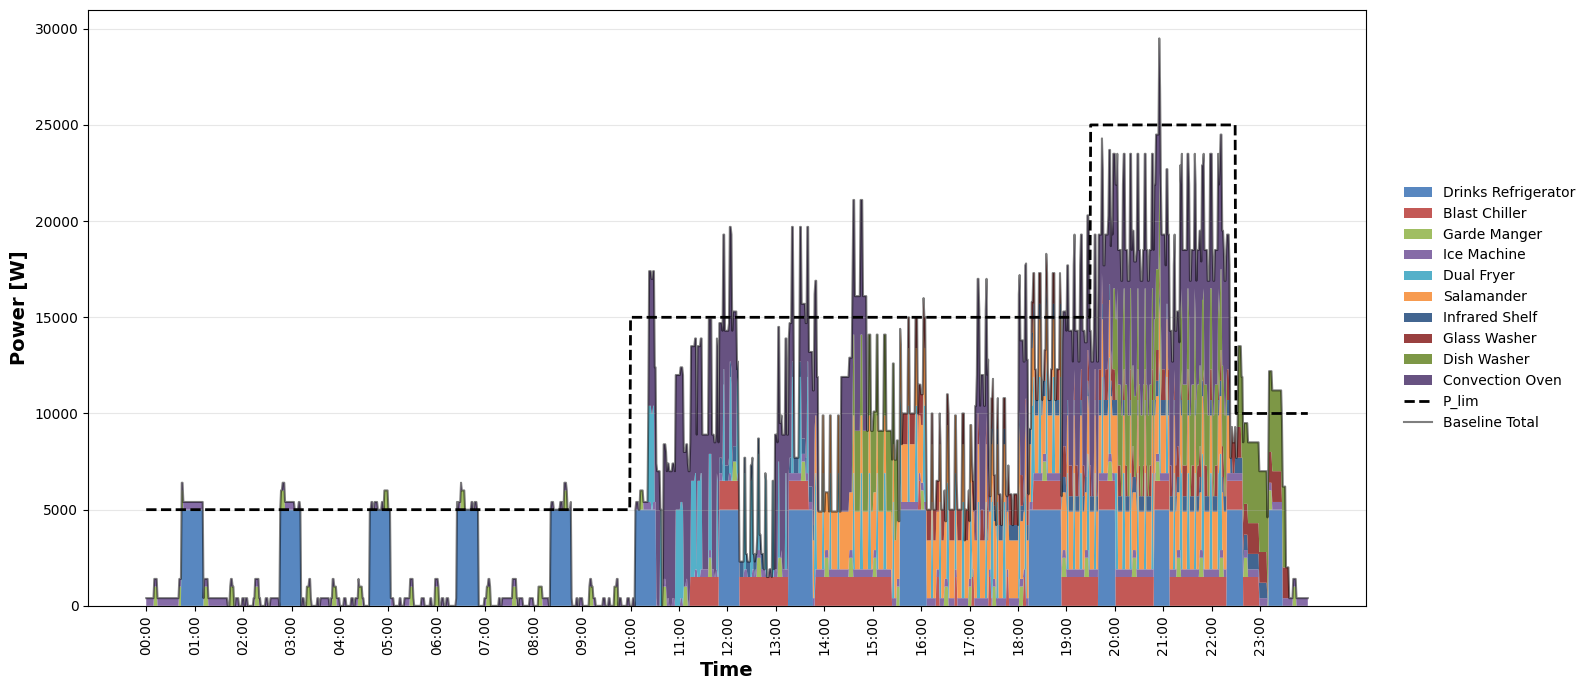

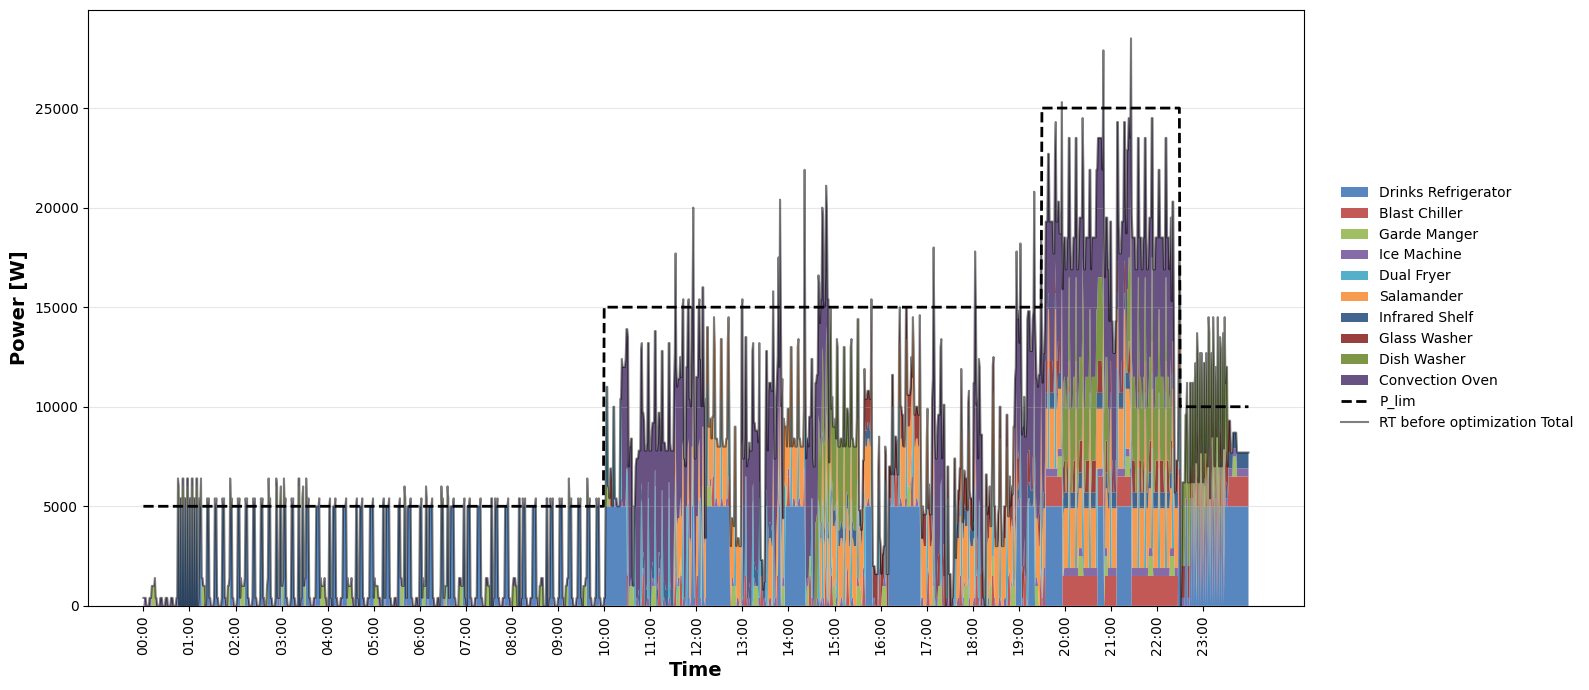

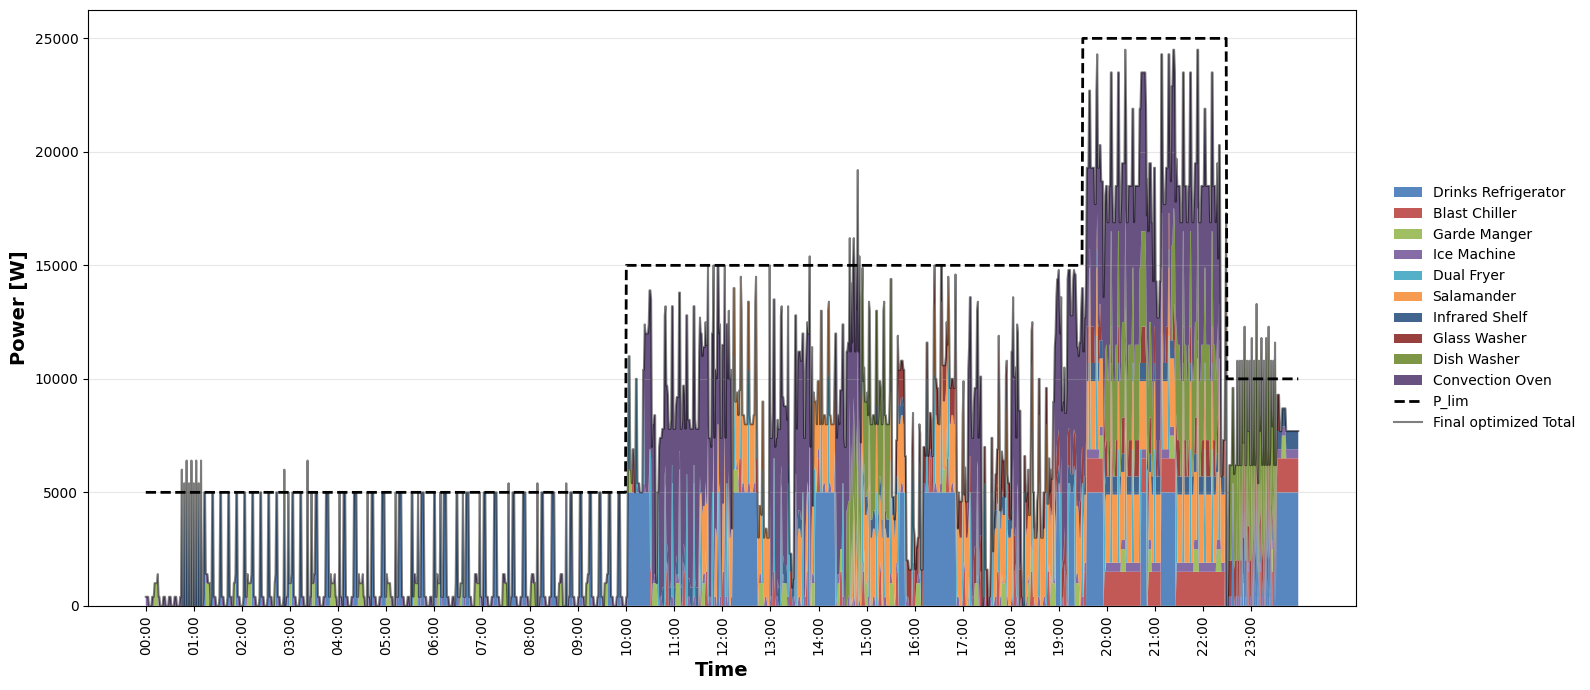

,case,energy_kWh,average_power_W,max_power_W
0,Baseline,178.193333,7424.722222,29500.0
1,RT before optimization,175.833333,7326.388889,28500.0
2,Final optimized,164.588333,6857.847222,24500.0


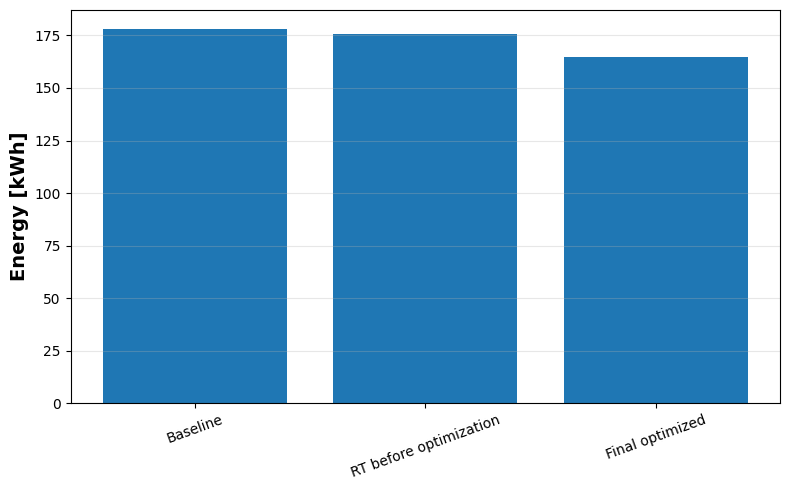

,case,n_violations_min,violation_time_h,max_power_W,max_excess_W,mean_excess_when_violating_W,total_excess_kWh,violation_reduction_vs_baseline_%,excess_energy_reduction_vs_baseline_%,peak_power_reduction_vs_baseline_%
0,Baseline,195,3.250000,29500.0,6100.0,1562.051282,5.076667,0.000000,0.000000,0.000000
1,RT before optimization,172,2.866667,28500.0,6900.0,1369.186047,3.925000,11.794872,22.685489,3.389831
2,Final optimized,36,0.600000,24500.0,4200.0,1169.444444,0.701667,81.538462,86.178595,16.949153


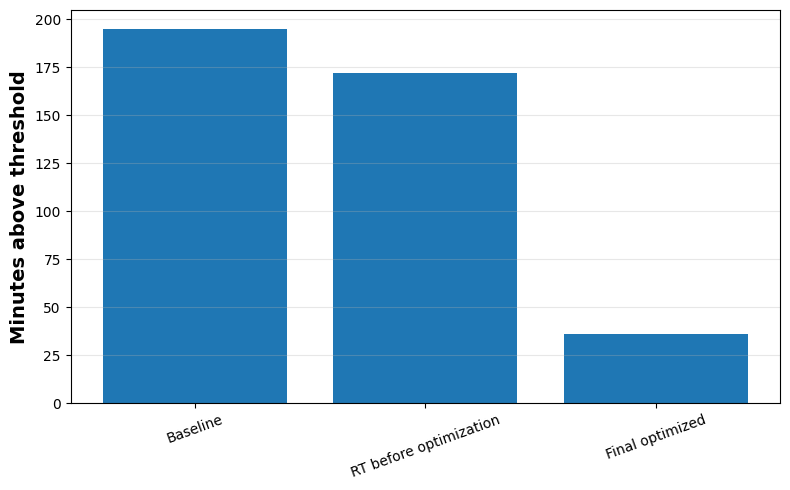

,case,shifted_energy_kWh,shifted_energy_pct_of_baseline
0,Baseline,0.000000,0.000000
1,RT before optimization,38.653333,21.691795
2,Final optimized,43.140000,24.209660


In [12]:
tz_start = 0
tz_end = 24 * 60

for case_name, data in power_cases.items():
    plot_stacked_power_case(
        case_name=case_name,
        P_dev=data["P_dev"],
        P_total=data["P_total"],
        P_lim_vector=P_lim_vector,
        dev_names=dev_names,
        colors=colors,
        tz_start=tz_start,
        tz_end=tz_end,
        tick_step=60
    )

consumption_24h_df = compute_consumption_metrics(
    power_cases,
    tz_start=tz_start,
    tz_end=tz_end
)

display(consumption_24h_df)

plot_consumption_metrics(
    consumption_24h_df,
    title="24h Energy Consumption"
)

peak_24h_df = compute_peak_metrics(
    power_cases,
    P_lim_vector,
    tz_start=tz_start,
    tz_end=tz_end
)

display(peak_24h_df)

plot_peak_metrics(
    peak_24h_df,
    title="24h Threshold Violations"
)

shifted_24h_df = compute_shifted_energy_metrics(
    power_cases,
    baseline_case="Baseline",
    tz_start=tz_start,
    tz_end=tz_end
)

display(shifted_24h_df)

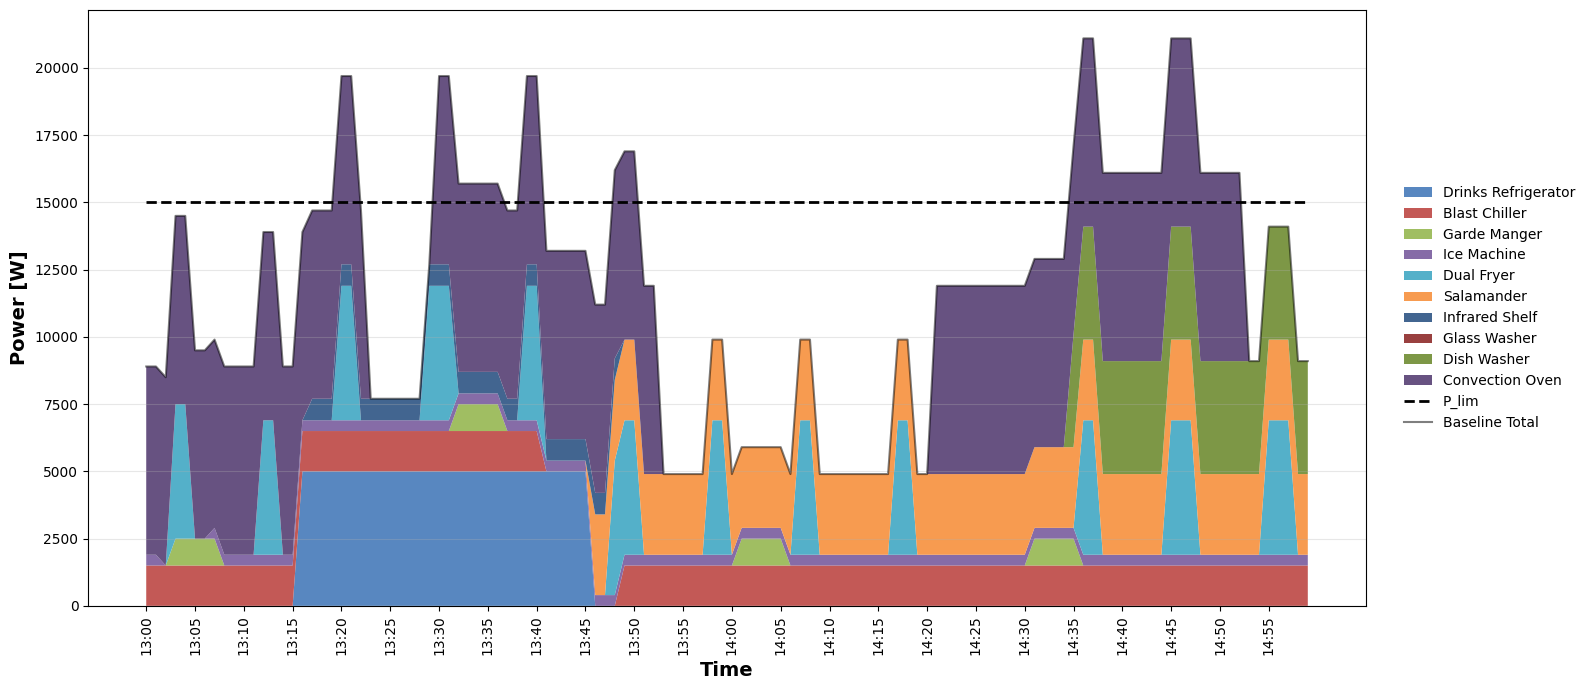

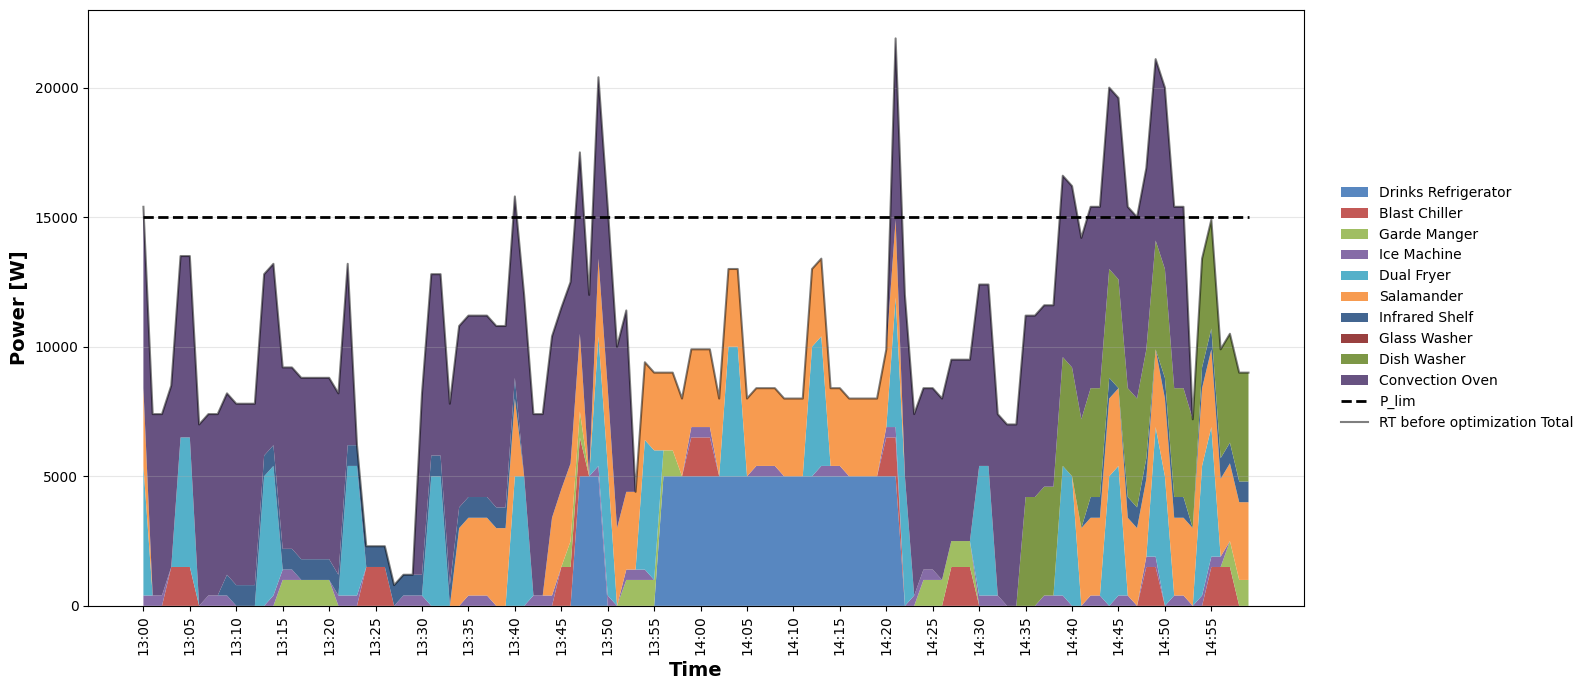

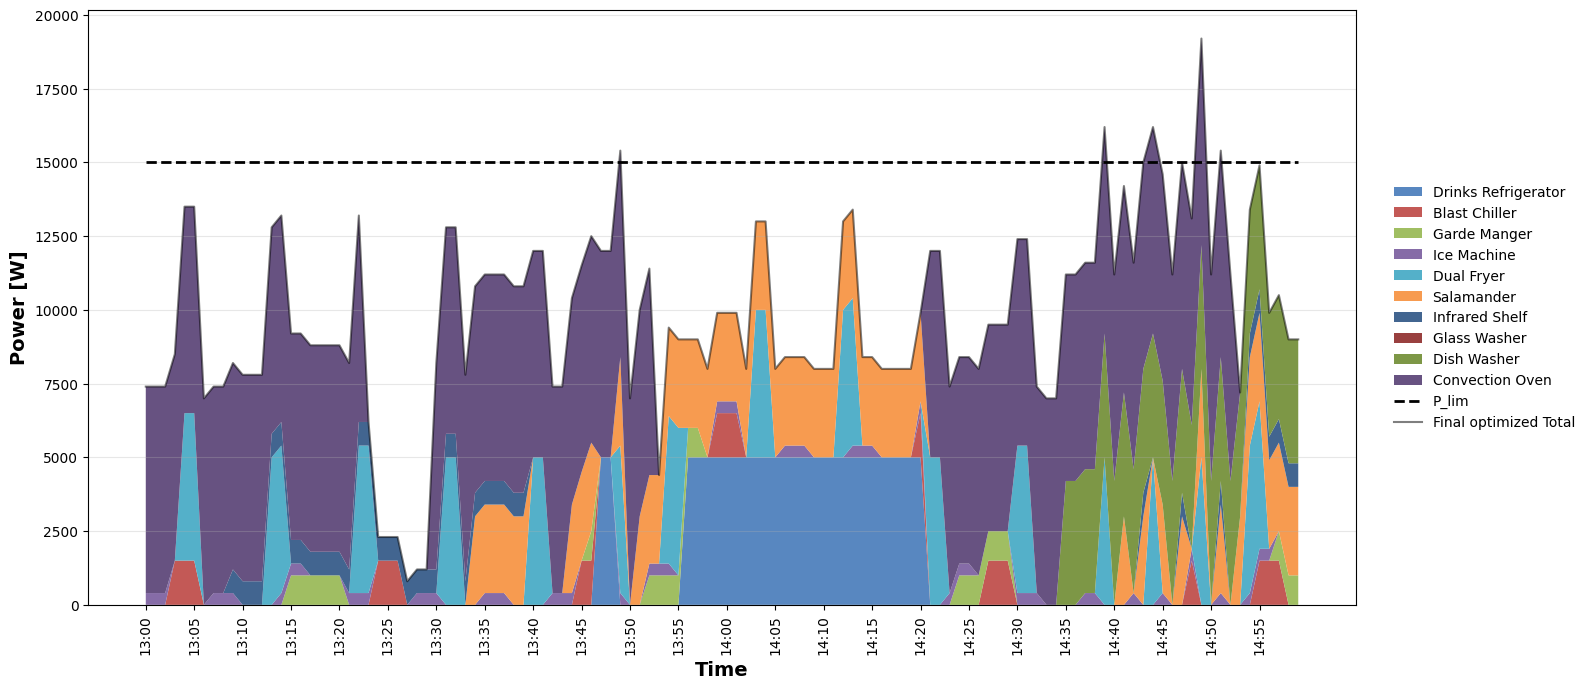

,case,energy_kWh,average_power_W,max_power_W
0,Baseline,23.710,11855.0,21100.0
1,RT before optimization,20.990,10495.0,21900.0
2,Final optimized,19.625,9812.5,19200.0


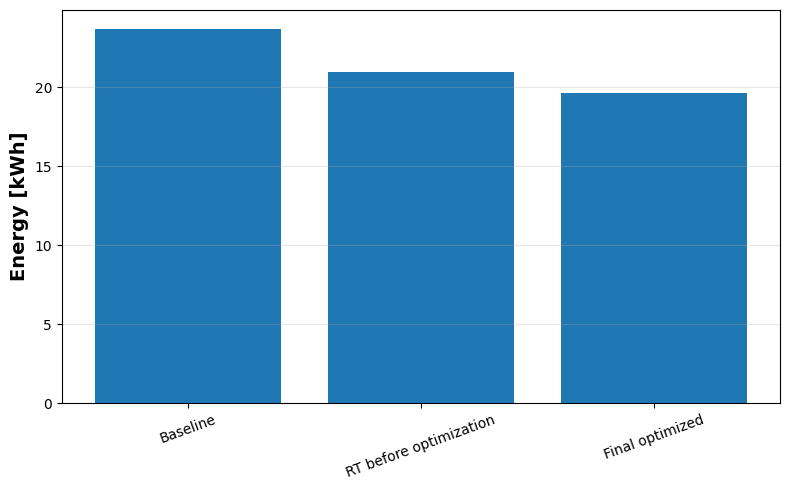

,case,n_violations_min,violation_time_h,max_power_W,max_excess_W,mean_excess_when_violating_W,total_excess_kWh,violation_reduction_vs_baseline_%,excess_energy_reduction_vs_baseline_%,peak_power_reduction_vs_baseline_%
0,Baseline,32,0.533333,21100.0,6100.0,2578.125000,1.375000,0.000,0.000000,0.000000
1,RT before optimization,18,0.300000,21900.0,6900.0,2433.333333,0.730000,43.750,46.909091,-3.791469
2,Final optimized,5,0.083333,19200.0,4200.0,1480.000000,0.123333,84.375,91.030303,9.004739


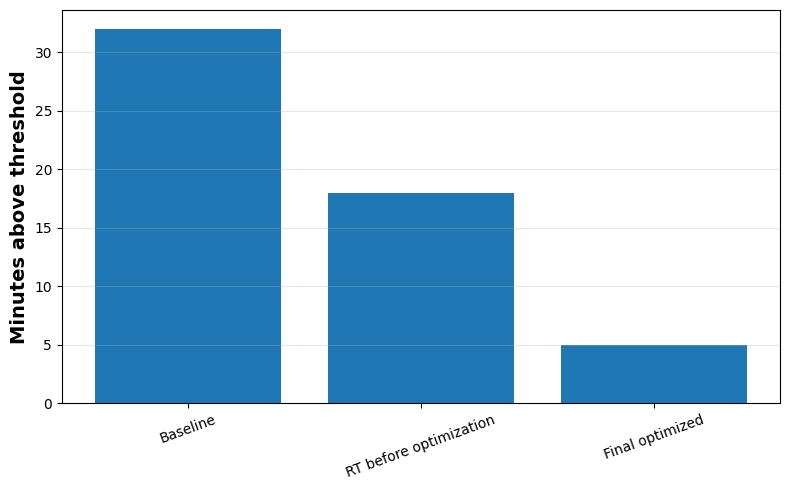

In [21]:
tz_start = 13 * 60
tz_end = 15 * 60

for case_name, data in power_cases.items():
    plot_stacked_power_case(
        case_name=case_name,
        P_dev=data["P_dev"],
        P_total=data["P_total"],
        P_lim_vector=P_lim_vector,
        dev_names=dev_names,
        colors=colors,
        tz_start=tz_start,
        tz_end=tz_end,
        tick_step=5
    )

consumption_20_22_df = compute_consumption_metrics(
    power_cases,
    tz_start=tz_start,
    tz_end=tz_end
)

display(consumption_20_22_df)

plot_consumption_metrics(
    consumption_20_22_df,
    title="20:00–22:00 Energy Consumption"
)

peak_20_22_df = compute_peak_metrics(
    power_cases,
    P_lim_vector,
    tz_start=tz_start,
    tz_end=tz_end
)

display(peak_20_22_df)

plot_peak_metrics(
    peak_20_22_df,
    title="20:00–22:00 Threshold Violations"
)

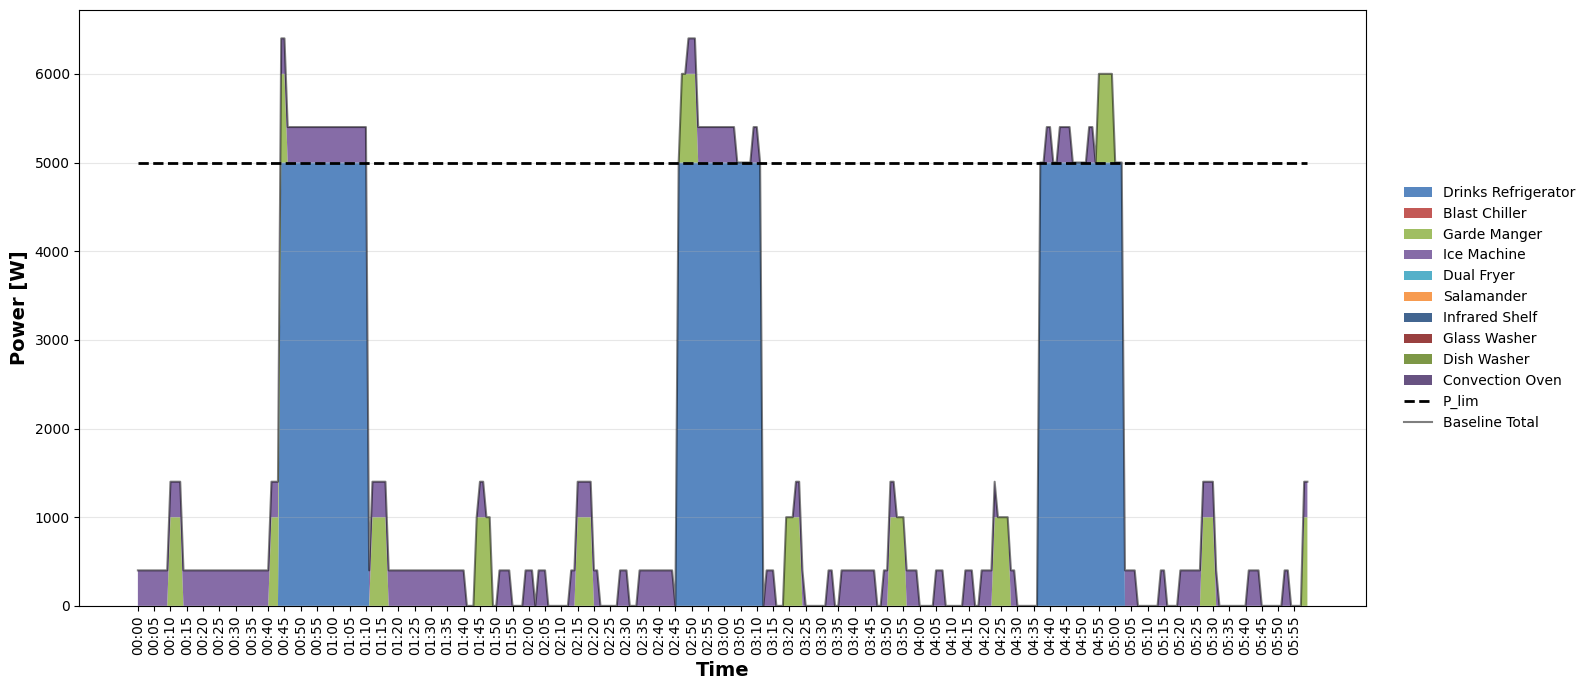

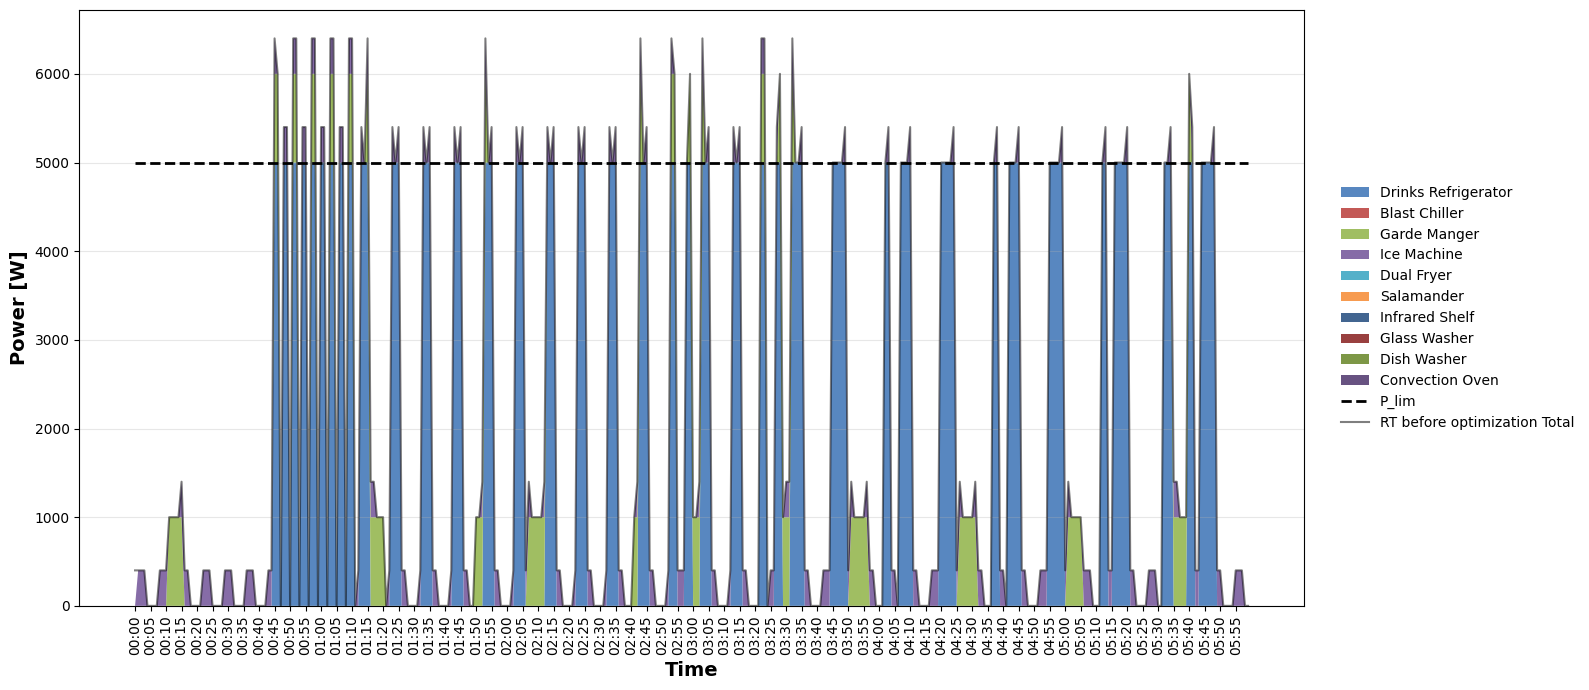

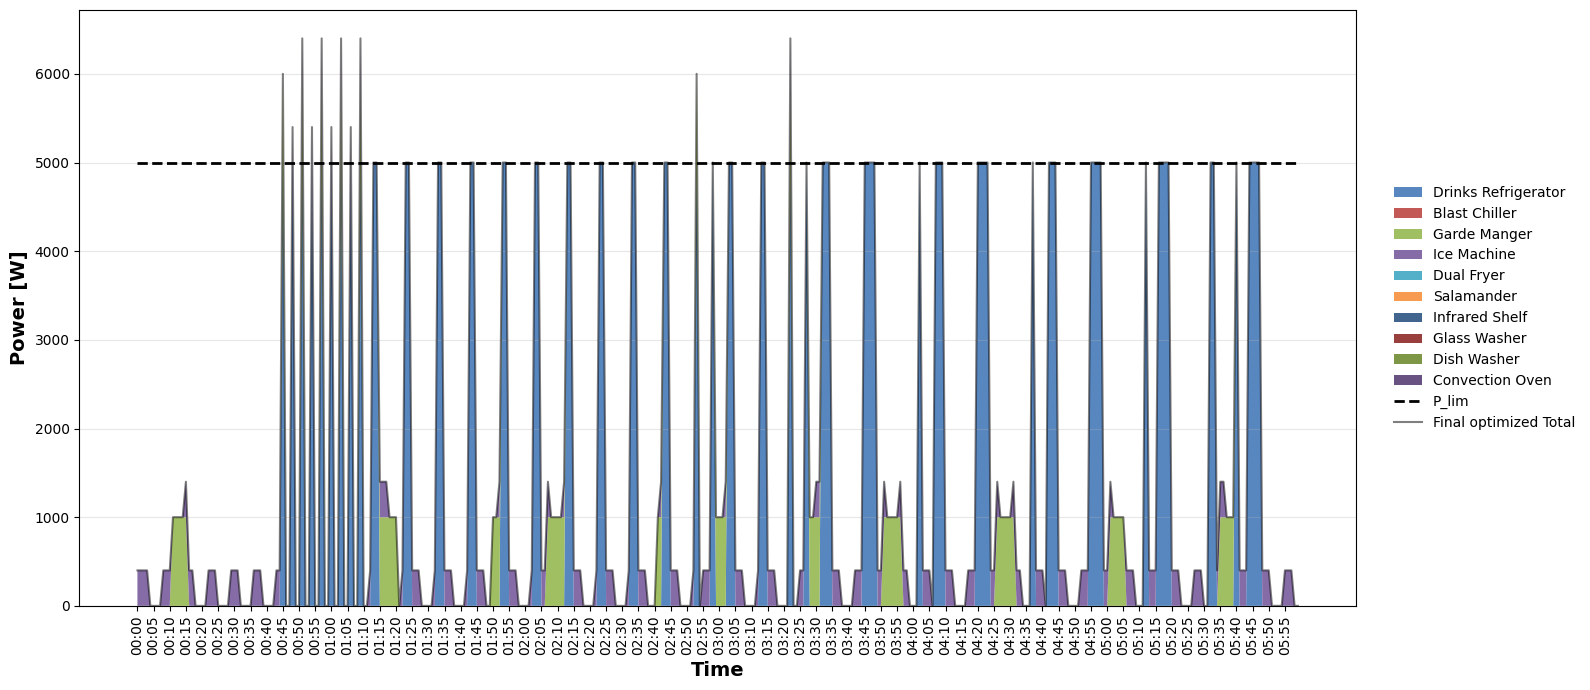

,case,energy_kWh,average_power_W,max_power_W
0,Baseline,9.013333,1502.222222,6400.0
1,RT before optimization,11.510000,1918.333333,6400.0
2,Final optimized,7.976667,1329.444444,6400.0


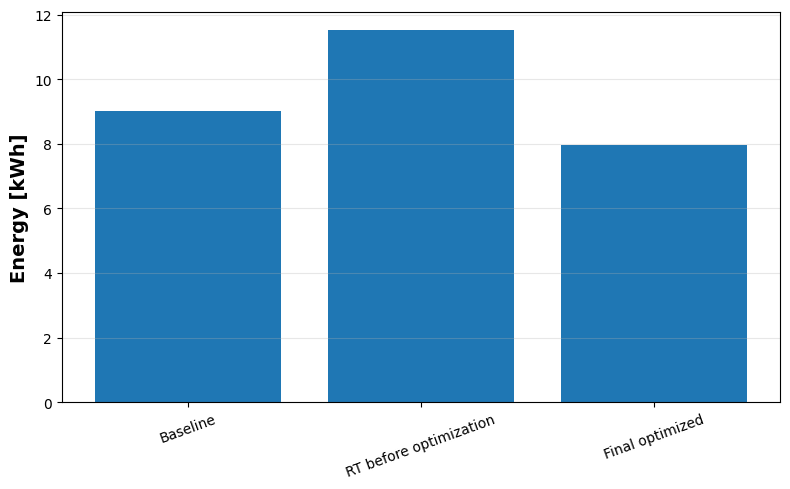

,case,n_violations_min,violation_time_h,max_power_W,max_excess_W,mean_excess_when_violating_W,total_excess_kWh,violation_reduction_vs_baseline_%,excess_energy_reduction_vs_baseline_%,peak_power_reduction_vs_baseline_%
0,Baseline,59,0.983333,6400.0,1400.0,555.932203,0.546667,0.000000,0.000000,0.0
1,RT before optimization,64,1.066667,6400.0,1400.0,712.500000,0.760000,-8.474576,-39.024390,0.0
2,Final optimized,11,0.183333,6400.0,1400.0,963.636364,0.176667,81.355932,67.682927,0.0


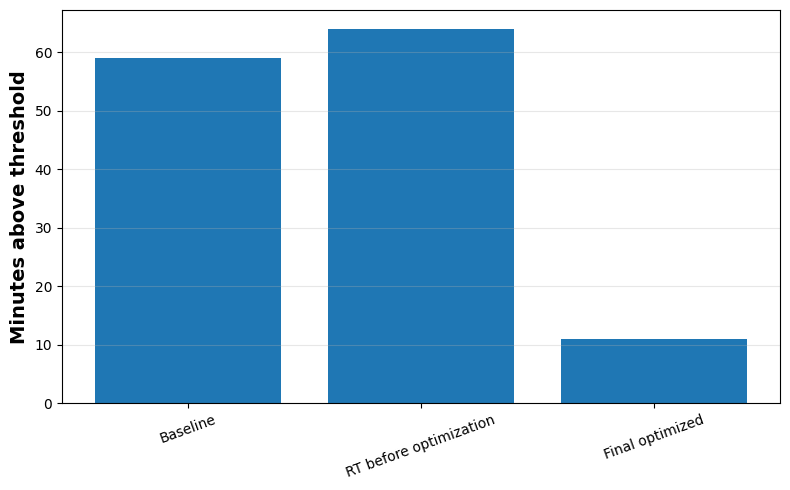

In [21]:
tz_start = 0
tz_end = 6 * 60

for case_name, data in power_cases.items():
    plot_stacked_power_case(
        case_name=case_name,
        P_dev=data["P_dev"],
        P_total=data["P_total"],
        P_lim_vector=P_lim_vector,
        dev_names=dev_names,
        colors=colors,
        tz_start=tz_start,
        tz_end=tz_end,
        tick_step=5
    )

consumption_20_22_df = compute_consumption_metrics(
    power_cases,
    tz_start=tz_start,
    tz_end=tz_end
)

display(consumption_20_22_df)

plot_consumption_metrics(
    consumption_20_22_df,
    title="20:00–22:00 Energy Consumption"
)

peak_20_22_df = compute_peak_metrics(
    power_cases,
    P_lim_vector,
    tz_start=tz_start,
    tz_end=tz_end
)

display(peak_20_22_df)

plot_peak_metrics(
    peak_20_22_df,
    title="20:00–22:00 Threshold Violations"
)

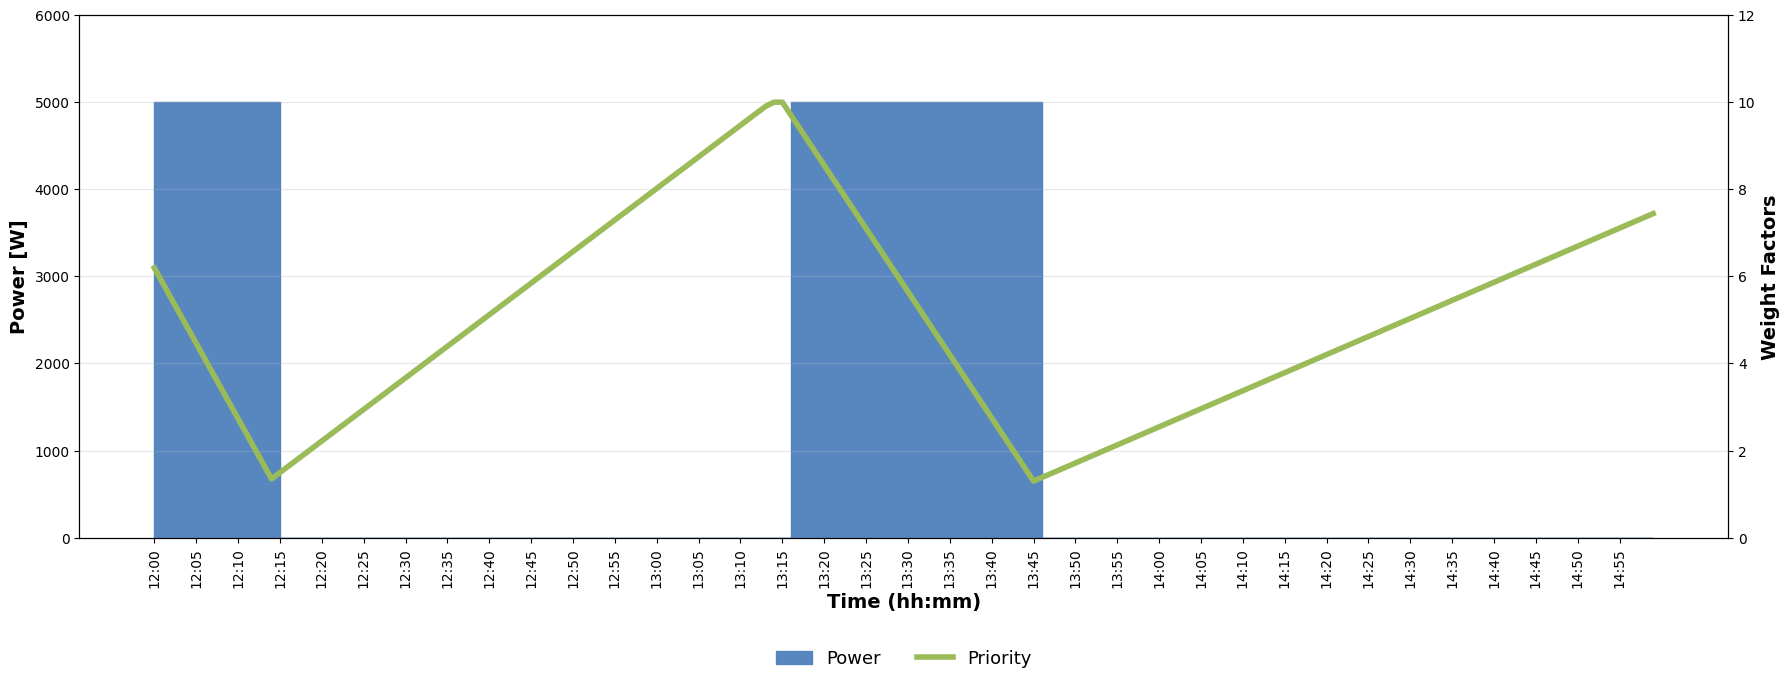

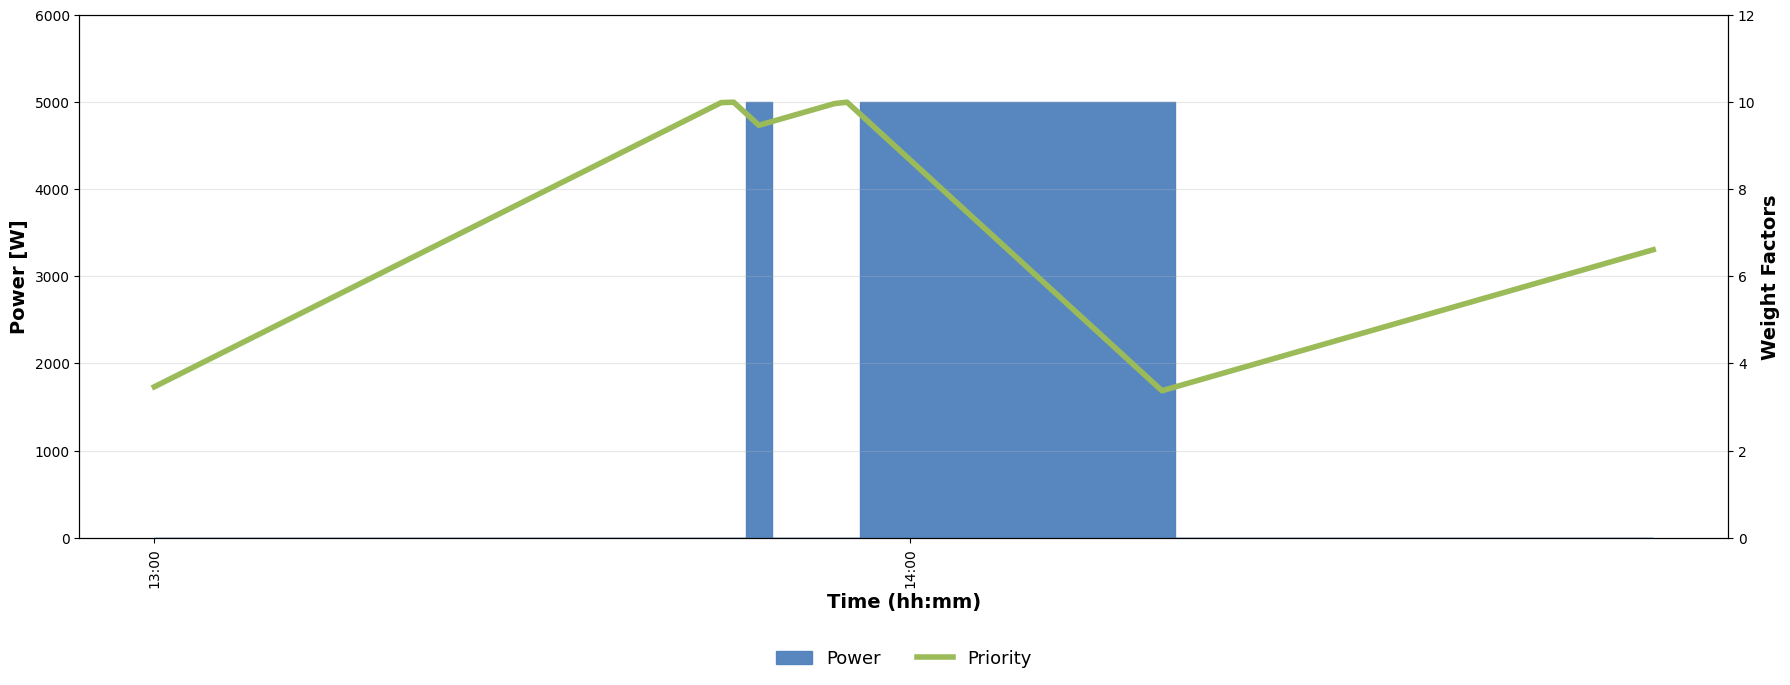

In [23]:
def plot_power_weight_device_flexible(
    P_dev_day,
    W_day,
    dev_idx,
    dev_name,
    day_start_dt,
    start_min=0,
    end_min=None,
    title=None,
    tick_step=60
):
    """
    Plot Power and Weight for a device over a flexible time period.
    
    Parameters:
    -----------
    P_dev_day : ndarray
        Power matrix (T, N_DEV)
    W_day : ndarray
        Weight matrix (T, N_DEV)
    dev_idx : int
        Device index
    dev_name : str
        Device name
    day_start_dt : datetime
        Start datetime of the day
    start_min : int
        Start minute (default: 0)
    end_min : int or None
        End minute (default: None = full 24h)
    title : str or None
        Custom title
    tick_step : int
        Step for x-axis ticks
    """
    if end_min is None:
        end_min = DAY_MINUTES
    
    minutes = np.arange(start_min, end_min)
    timestamps = [
        (day_start_dt + timedelta(minutes=int(i))).strftime("%H:%M")
        for i in minutes
    ]
    
    power = P_dev_day[start_min:end_min, dev_idx]
    weight = W_day[start_min:end_min, dev_idx]
    
    # Plotar com índices relativos (0 a len-1)
    x_plot = np.arange(len(minutes))
    
    fig, ax1 = plt.subplots(figsize=(18, 7))
    
    # Power - azul
    ax1.fill_between(
        x_plot,
        power,
        step="post",
        color="#4F81BD",
        alpha=0.95,
        label="Power"
    )
    
    ax1.set_ylabel("Power [W]", fontsize=14, fontweight="bold")
    ax1.set_xlabel("Time (hh:mm)", fontsize=14, fontweight="bold")
    ax1.set_ylim(0, max(power.max() * 1.2, 1200))
    ax1.grid(axis="y", alpha=0.3)
    
    # Weight - eixo secundário
    ax2 = ax1.twinx()
    
    ax2.plot(
        x_plot,
        weight,
        color="#9BBB59",
        linewidth=4,
        label="Priority"
    )
    
    ax2.set_ylabel("Weight Factors", fontsize=14, fontweight="bold")
    ax2.set_ylim(0, 12)
    
    # X-axis labels
    tick_positions = np.arange(0, len(x_plot), tick_step)
    ax1.set_xticks(tick_positions)
    ax1.set_xticklabels([timestamps[i] if i < len(timestamps) else "" for i in tick_positions], rotation=90)
    
    if title is None:
        title = f"Power and Priority - {dev_name}"
        
    # legenda conjunta
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    
    ax1.legend(
        lines_1 + lines_2,
        labels_1 + labels_2,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.28),
        ncol=2,
        frameon=False,
        fontsize=13
    )
    
    plt.tight_layout()
    plt.show()
    
# Baseline
plot_power_weight_device_flexible(
    P_dev_day=power_cases["Baseline"]["P_dev"],
    W_day=W_before_opt_RT,
    dev_idx=0,
    dev_name=dev_names[0],
    day_start_dt=day_start_dt,
    start_min=12*60,
    end_min=15*60,
    title=f"{dev_names[0]} - Baseline 13:00-15:00",
    tick_step=5
)

# Optimized
plot_power_weight_device_flexible(
    P_dev_day=power_cases["Final optimized"]["P_dev"],
    W_day=W_RT_matrix,
    dev_idx=0,
    dev_name=dev_names[0],
    day_start_dt=day_start_dt,
    start_min=13*60,
    end_min=15*60,
    title=f"{dev_names[0]} - Optimized 13:00-15:00",
    tick_step=60
)